# Advection–Diffusion Plume Conditioning

This notebook reproduces the advection–diffusion experiment of *LatentFlow: A General Framework for Conditioning Stochastic Processes* (Sharrock, Astfalck & Moss, 2026; Figures 5 and 17). A pollutant is released continuously from an uncertain source and carried by a randomly varying wind:

$$\partial_t c + \mathbf{w}(t)\cdot\nabla c = D\,\Delta c + q\,s(\mathbf{x}),\qquad d\mathbf{w} = \theta(\bar{\mathbf{w}} - \mathbf{w})\,dt + \sigma_w\,d\mathbf{W}_t,$$

on the unit square. The source position, release rate and diffusivity are random, and the wind is an Ornstein–Uhlenbeck process. All of this randomness comes from just **160** Gaussian innovations: 6 for the source, initial wind and diffusivity, and 2 per time step for the wind. Guidance then conditions the plume on

1. **sparse sensors**: noisy concentrations at 8 locations, observed at 4 times;
2. **obstacle avoidance**: the concentration must stay below $0.06$ in a central zone at all times;
3. **a detector hit**: the peak concentration in a downstream detector must exceed $0.40$, which fewer than 1% of prior plumes achieve.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Rectangle

from flow_inference.conditions import BinaryCondition, EqualityCondition
from flow_inference.flows import GaussianIncrementFlow
from flow_inference.guidance import GuidanceMC
from flow_inference.maps import BaseMap
from flow_inference.sampler import IntegratorSampler

torch.set_default_dtype(torch.float64)

## 1. Configuration

A $40 \times 40$ grid on the unit square and 77 wind steps up to $t = 2.2$. Row 0 of every image is the top of the domain ($y = 1$).

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)

G = 40  # grid size
NUM_WIND_STEPS = 77  # wind innovations / solver steps
T_FINAL = 2.2
DT = T_FINAL / NUM_WIND_STEPS
NUM_FRAMES = NUM_WIND_STEPS + 1  # the field is returned at every step, starting from c = 0
num_samples = 4
NUM_STEPS = 100  # flow integration steps

SNAP_TIMES = [0.3, 0.7, 1.1, 1.6, 2.0, 2.2]
SNAP_FRAMES = [round(t / DT) for t in SNAP_TIMES]
CMAP, VMIN, VMAX, FIELD_LABEL = "viridis", 0.0, 0.6, "concentration"

centres = (torch.arange(G, device=device) + 0.5) / G
YY, XX = torch.meshgrid(1.0 - centres, centres, indexing="ij")  # row 0 is y = 1

OBSTACLE = (0.42, 0.60, 0.42, 0.62)  # (x0, x1, y0, y1)
DETECTOR = (0.78, 0.95, 0.72, 0.92)
OBSTACLE_MAX, DETECTOR_MIN = 0.06, 0.40

## 2. The plume simulator

`PlumeMap` is the generator $T_\vartheta$. Each wind step is split into four first-order upwind substeps, which keeps the explicit scheme stable; a `tanh` soft-clamp bounds the wind speed. The domain has zero-concentration boundaries, so material is advected out of the box.

In [3]:
class PlumeMap(BaseMap):
    """Latent (B, 1, 6 + 2 * NUM_WIND_STEPS) -> concentration fields (B, 1, NUM_FRAMES * G * G)."""

    def __init__(self, wind_mean=(0.32, 0.14), theta=1.0, wind_sd=0.25, diffusivity=0.002, rate=0.03,
                 source_width=0.03, substeps=4):
        super().__init__(latent_dim=6 + 2 * NUM_WIND_STEPS, output_shape=(NUM_FRAMES, G, G), device=device)
        self.register_buffer("wind_mean", torch.tensor(wind_mean, device=device))
        self.theta, self.wind_sd, self.diffusivity, self.rate = theta, wind_sd, diffusivity, rate
        self.source_width, self.substeps = source_width, substeps

    def _map(self, z):
        B = z.shape[0]
        z = z[:, 0]
        dx = 1.0 / G
        x_src = 0.15 + 0.03 * z[:, 0]
        y_src = 0.45 + 0.08 * z[:, 1]
        rate = self.rate * torch.exp(0.3 * z[:, 2])
        wind = self.wind_mean[None] + 0.08 * z[:, 3:5]
        diffusivity = self.diffusivity * torch.exp(0.3 * z[:, 5])
        wind_noise = z[:, 6:].reshape(B, NUM_WIND_STEPS, 2)

        dist2 = (XX[None] - x_src[:, None, None]) ** 2 + (YY[None] - y_src[:, None, None]) ** 2
        source = torch.exp(-dist2 / (2 * self.source_width**2))
        source = source / source.mean(dim=(1, 2), keepdim=True)  # unit mass on the unit square
        emission = rate[:, None, None] * source
        diff = diffusivity[:, None, None]

        c = torch.zeros(B, G, G, device=z.device, dtype=z.dtype)
        frames = [c]
        h = DT / self.substeps
        for k in range(NUM_WIND_STEPS):
            w = 0.8 * torch.tanh(wind / 0.8)  # soft speed limit, for the CFL condition
            u, v = w[:, 0, None, None], w[:, 1, None, None]
            for _ in range(self.substeps):
                p = torch.nn.functional.pad(c, (1, 1, 1, 1))  # zero boundary
                left, right = p[:, 1:-1, :-2], p[:, 1:-1, 2:]
                up, down = p[:, :-2, 1:-1], p[:, 2:, 1:-1]  # up = larger y
                dc_dx = torch.where(u > 0, c - left, right - c) / dx
                dc_dy = torch.where(v > 0, c - down, up - c) / dx
                laplacian = (left + right + up + down - 4 * c) / dx**2
                c = c + h * (-u * dc_dx - v * dc_dy + diff * laplacian + emission)
            wind = wind + self.theta * (self.wind_mean[None] - wind) * DT + self.wind_sd * DT**0.5 * wind_noise[:, k]
            frames.append(c)
        return torch.stack(frames, dim=1).reshape(B, 1, -1)


flow = GaussianIncrementFlow(map=PlumeMap(), device=device)
sampler = IntegratorSampler(flow=flow)

## 3. Helpers

`sample` draws prior or guided fields, and `plot_snapshots` lays several regimes out as in the paper: two draws per regime, one row each, at six times.

In [4]:
def sample(condition=None):
    """`num_samples` fields (B, num_frames, G, G): the prior if `condition` is None, else guided."""
    guidance = None if condition is None else GuidanceMC(flow, condition).to(device)
    out = sampler.sample(num_samples, guidance=guidance, num_steps=NUM_STEPS).detach()
    return out.reshape(num_samples, NUM_FRAMES, G, G)


def plot_snapshots(regimes, draws=2, overlay=None):
    """Rows: `draws` samples of each regime; columns: the fields at SNAP_TIMES.

    `regimes` is a list of (label, samples); `overlay(ax, label, frame)` draws a regime's
    condition on a panel.
    """
    rows = len(regimes) * draws
    fig, axes = plt.subplots(rows, len(SNAP_FRAMES), figsize=(1.7 * len(SNAP_FRAMES) + 1.6, 1.7 * rows),
                             squeeze=False)
    for r, (label, samples) in enumerate(regimes):
        for d in range(draws):
            row = r * draws + d
            for col, frame in enumerate(SNAP_FRAMES):
                ax = axes[row, col]
                im = ax.imshow(samples[d, frame].cpu(), cmap=CMAP, vmin=VMIN, vmax=VMAX)
                ax.set_xticks([])
                ax.set_yticks([])
                if overlay is not None:
                    overlay(ax, label, frame)
                if row == 0:
                    ax.set_title(f"t = {frame * DT:.2f}", fontsize=9)
            if d == 0:
                axes[row, 0].set_ylabel(label, fontsize=10, fontweight="bold")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label=FIELD_LABEL)
    return fig


def draw_box(ax, box, color, label=None):
    """Outline a (x0, x1, y0, y1) box of the unit square on an image panel (row 0 is y = 1)."""
    x0, x1, y0, y1 = box
    ax.add_patch(Rectangle((x0 * G - 0.5, (1 - y1) * G - 0.5), (x1 - x0) * G, (y1 - y0) * G,
                           fill=False, edgecolor=color, linewidth=1.6, linestyle="--"))
    if label:
        ax.text((x0 + x1) / 2 * G - 0.5, (1 - (y0 + y1) / 2) * G - 0.5, label, color=color,
                ha="center", va="center", fontsize=9, fontweight="bold")


def box_mask(box):
    """(G, G) boolean mask of the pixels whose centres lie in a (x0, x1, y0, y1) box."""
    x0, x1, y0, y1 = box
    return (XX >= x0) & (XX <= x1) & (YY >= y0) & (YY <= y1)


def smooth_max(values, tau):
    """Log-sum-exp maximum over the last axis: differentiable, within tau * log(n) of the hard max."""
    return tau * torch.logsumexp(values / tau, dim=-1)

## 4. Prior

The plume's direction, spread and strength all vary from draw to draw.

  0%|          | 0/99 [00:00<?, ?it/s]

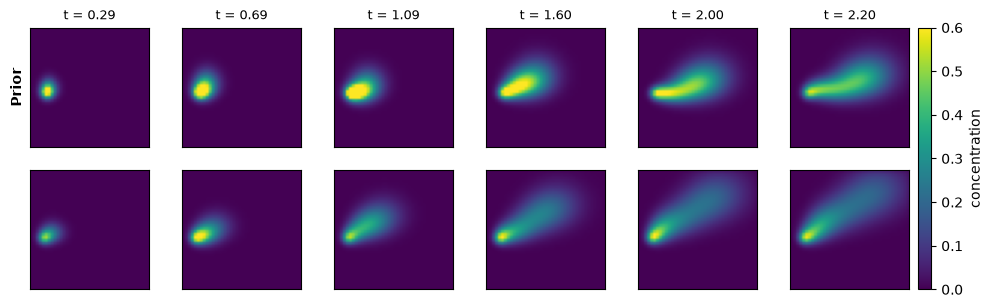

In [5]:
prior_samples = sample()
plot_snapshots([("Prior", prior_samples)]);

## 5. Sparse sensors

Take one prior plume as the "truth" and observe it at 8 sensors at 4 times, with noise of standard deviation $0.02$. `SensorObservation` is an `EqualityCondition` whose `sigma` is that noise level.

  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/99 [00:00<?, ?it/s]

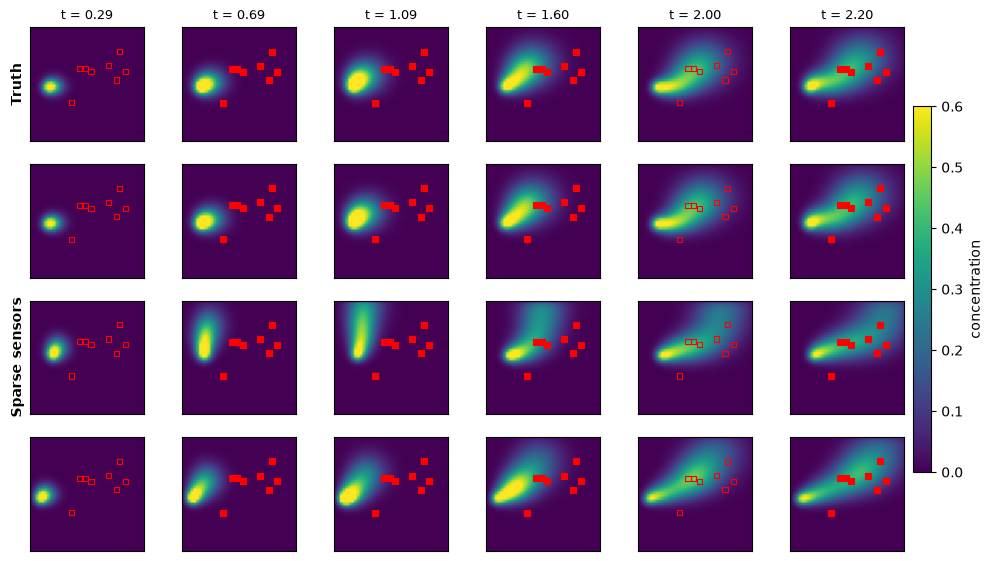

In [6]:
truth = sample()[0]
generator = torch.Generator(device=device).manual_seed(SEED)
region = ((XX > 0.3) & (XX < 0.9) & (YY > 0.3) & (YY < 0.8)).reshape(-1).nonzero().squeeze(1)
sensors = region[torch.randperm(region.numel(), device=device, generator=generator)[:8]]  # flat pixel indices
sensor_frames = torch.tensor([round(t / DT) for t in (0.7, 1.1, 1.6, 2.2)], device=device)
OBS_NOISE = 0.02
observations = truth.reshape(NUM_FRAMES, -1)[sensor_frames][:, sensors]
observations = observations + OBS_NOISE * torch.randn(observations.shape, device=device, generator=generator)


class SensorObservation(EqualityCondition):
    """Noisy point observations: the field at `pixels` in each of `frames` equals `observations`."""

    def __init__(self, frames, pixels, observations, sigma):
        super().__init__(sigma=sigma)
        self.register_buffer("frames", frames)
        self.register_buffer("pixels", pixels)
        self.register_buffer("observations", observations)  # (num_frames, num_pixels)

    def residual(self, x):
        fields = x.reshape(x.shape[0], NUM_FRAMES, -1)[:, self.frames][:, :, self.pixels]
        return (fields - self.observations[None]).reshape(x.shape[0], 1, -1)


sensor_samples = sample(SensorObservation(sensor_frames, sensors, observations, sigma=OBS_NOISE))


def draw_sensors(ax, frame):
    active = frame in sensor_frames.tolist()
    ax.scatter((sensors % G).cpu(), (sensors // G).cpu(), s=14, marker="s",
               facecolors="red" if active else "none", edgecolors="red", linewidths=0.8)


plot_snapshots([("Truth", truth[None].expand(2, -1, -1, -1)), ("Sparse sensors", sensor_samples)],
               overlay=lambda ax, label, frame: draw_sensors(ax, frame));

Filled squares mark the sensors at the times they are read. The truth row repeats the single ground-truth plume.

## 6. Obstacle avoidance and detector hit

Both are binary events on the peak concentration in a box over the whole run, relaxed with a smooth maximum. `BoxPeak` returns a positive margin when the event holds: below a ceiling for the obstacle, above a floor for the detector.

The log-sum-exp maximum overestimates the true maximum by up to $\tau \log n$, and here $n$ is every pixel in the box at every time step (about 12,000). With $\tau = 0.002$ that bias is below $0.02$; a larger $\tau$ would put the obstacle ceiling of $0.06$ out of reach, and guidance would respond by switching the release off.

The mean wind blows straight at the obstacle, so avoiding it genuinely favours plumes that are deflected or weaker. A sharp relaxation (small `v`) over-weights the second route and leaves only a faint plume; the obstacle uses the softer `v = 0.01`.

In [7]:
class BoxPeak(BinaryCondition):
    """Peak concentration in `box` over all times below `level` (above=False) or above it (above=True)."""

    def __init__(self, box, level, above, v=1e-3, smooth_tau=0.002):
        super().__init__(v=v)
        self.register_buffer("mask", box_mask(box).reshape(-1))
        self.level, self.sign, self.smooth_tau = level, 1.0 if above else -1.0, smooth_tau

    def smooth_eval_condition(self, x):
        inside = x.reshape(x.shape[0], NUM_FRAMES, -1)[:, :, self.mask].reshape(x.shape[0], -1)
        margin = self.sign * (smooth_max(inside, self.smooth_tau) - self.level)
        return margin[:, None, None]


def event_rate(condition, samples):
    return (condition.smooth_eval_condition(samples.reshape(samples.shape[0], 1, -1)) > 0).double().mean().item()


def prior_rate(condition, num=2000, chunk=400):
    """Event rate over `num` prior draws, simulated in chunks to bound memory."""
    hits = 0
    for _ in range(num // chunk):
        fields = flow.map(torch.randn(chunk, 1, flow.latent_dim, device=device))
        hits += (condition.smooth_eval_condition(fields) > 0).sum().item()
    return hits / num


obstacle_condition = BoxPeak(OBSTACLE, OBSTACLE_MAX, above=False, v=1e-2)  # softer: see the note above
detector_condition = BoxPeak(DETECTOR, DETECTOR_MIN, above=True)
obstacle_samples = sample(obstacle_condition)
detector_samples = sample(detector_condition)

for name, condition, guided in [("obstacle avoided", obstacle_condition, obstacle_samples),
                                ("detector hit", detector_condition, detector_samples)]:
    print(f"{name:17s} prior={prior_rate(condition):.4f}  guided={event_rate(condition, guided):.2f}")

  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/99 [00:00<?, ?it/s]

obstacle avoided  prior=0.0430  guided=1.00


detector hit      prior=0.0025  guided=1.00


## 7. Summary

The four regimes as in Figure 17 of the paper.

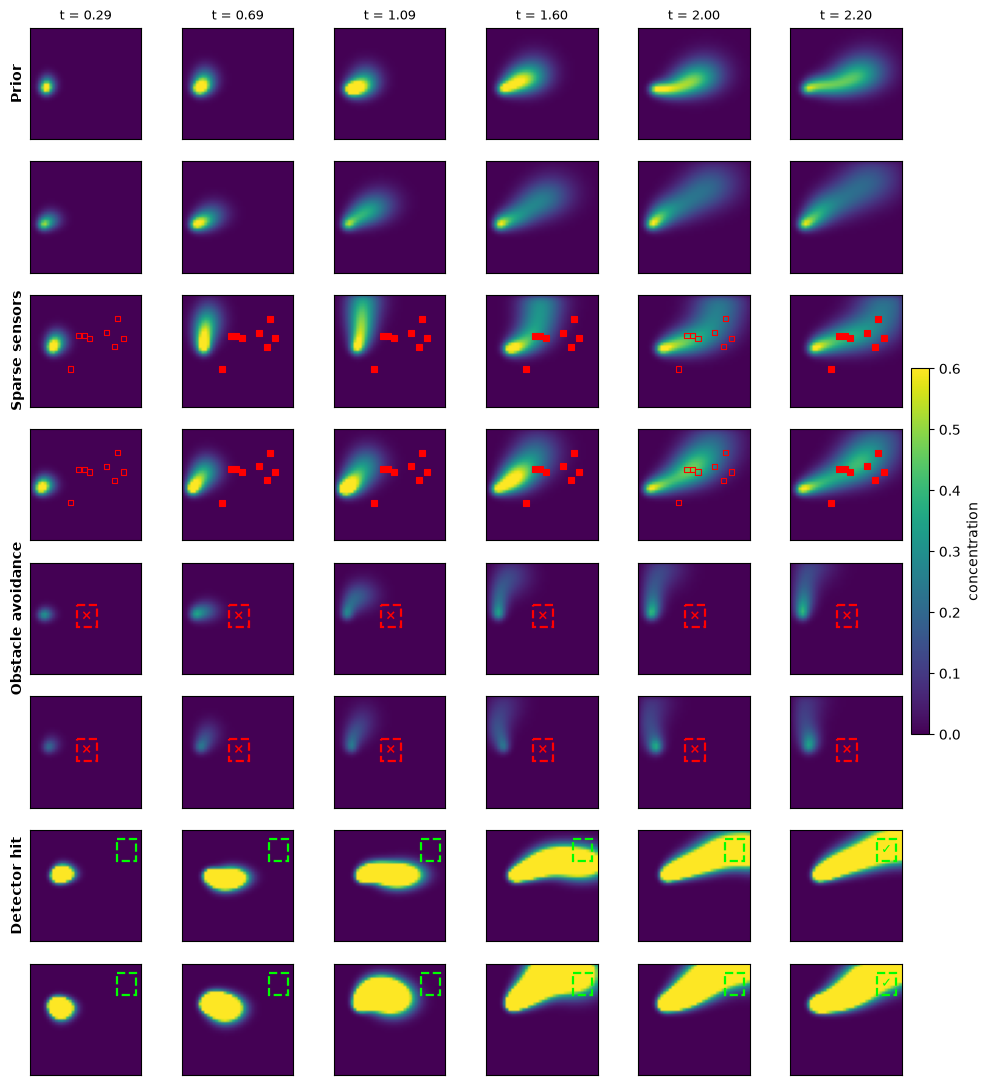

In [8]:
def overlay(ax, label, frame):
    if label == "Sparse sensors":
        draw_sensors(ax, frame)
    elif label == "Obstacle avoidance":
        draw_box(ax, OBSTACLE, "red", "×")
    elif label == "Detector hit":
        draw_box(ax, DETECTOR, "lime", "✓" if frame == SNAP_FRAMES[-1] else None)


plot_snapshots([
    ("Prior", prior_samples),
    ("Sparse sensors", sensor_samples),
    ("Obstacle avoidance", obstacle_samples),
    ("Detector hit", detector_samples),
], overlay=overlay);